# Business problem statement

A leading financial institution wants to develop an intelligent Anti-Money Laundering detection system using machine learning  to identify suspicious financial transactions. The existing rule-based system generates a large number of false alerts and fails to detect sophisticated money laundering patterns. The bank wants to leverage historical transaction data and customer behavioral patterns to build a predictive model that can classify transactions as legitimate or suspicious, thereby improving detection rates, reducing false positives, and supporting regulatory compliance

# Project Objective

The primary objective is to build a binary classification model using ANN to identify potentially suspicious financial transactions.

Technical objectives:
1. Analyze historical banking transaction data.
2. Perform exploratory data analysis (EDA).
3. Identify important transaction-level and customer-level features.
4. Handle missing values and categorical variables.
5. Apply feature scaling and preprocessing.
6. Handle imbalanced transaction classes.
7. Build an ANN architecture using TensorFlow/Keras.
8. Train the model to distinguish legitimate and suspicious transactions.
9. Optimize the model using hyperparameter tuning.
10. Evaluate the model using appropriate classification metrics.
11. Develop a prediction interface for real-time transaction monitoring.

#### 1 b) Data understanding

##### Data Collection

In [1]:
!pip install kagglehub

In [2]:
import kagglehub
import pandas as pd

In [7]:
link = r'berkanoztas/synthetic-transaction-monitoring-dataset-aml'
path = kagglehub.dataset_download(link)      # folder where the files were saved
print(path)
import os                                 # check the location
print(os.listdir(path))                       # check the file name inside

df = pd.read_csv(os.path.join(path, 'SAML-D.csv'))

Using Colab cache for faster access to the 'synthetic-transaction-monitoring-dataset-aml' dataset.
/kaggle/input/synthetic-transaction-monitoring-dataset-aml
['SAML-D.csv']


##### Data Description

In [8]:
df.shape

(9504852, 12)

In [9]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,2022-10-07,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,2022-10-07,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,2022-10-07,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,2022-10-07,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,2022-10-07,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [10]:
df['Payment_currency'].unique()

array(['UK pounds', 'Indian rupee', 'Albanian lek', 'Swiss franc',
       'Pakistani rupee', 'Naira', 'Yen', 'Euro', 'Dirham',
       'Mexican Peso', 'Turkish lira', 'US dollar', 'Moroccan dirham'],
      dtype=object)

In [11]:
df['Received_currency'].unique()

array(['UK pounds', 'Dirham', 'Pakistani rupee', 'Euro', 'US dollar',
       'Mexican Peso', 'Indian rupee', 'Albanian lek', 'Turkish lira',
       'Naira', 'Swiss franc', 'Yen', 'Moroccan dirham'], dtype=object)

In [12]:
df['Sender_bank_location'].unique()

array(['UK', 'Albania', 'Nigeria', 'Japan', 'Spain', 'Switzerland', 'UAE',
       'Italy', 'France', 'Pakistan', 'Mexico', 'Austria', 'Germany',
       'Turkey', 'India', 'Morocco', 'USA', 'Netherlands'], dtype=object)

In [13]:
df['Receiver_bank_location'].unique()

array(['UK', 'UAE', 'Spain', 'France', 'USA', 'Mexico', 'Albania',
       'Turkey', 'Nigeria', 'Switzerland', 'Italy', 'Germany', 'Austria',
       'Netherlands', 'India', 'Pakistan', 'Morocco', 'Japan'],
      dtype=object)

In [14]:
df['Payment_type'].unique()

array(['Cash Deposit', 'Cross-border', 'Cheque', 'ACH', 'Credit card',
       'Debit card', 'Cash Withdrawal'], dtype=object)

In [15]:
df.dtypes

,0
Time,object
Date,object
Sender_account,int64
Receiver_account,int64
Amount,float64
Payment_currency,object
Received_currency,object
Sender_bank_location,object
Receiver_bank_location,object
Payment_type,object


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Time                    object 
 1   Date                    object 
 2   Sender_account          int64  
 3   Receiver_account        int64  
 4   Amount                  float64
 5   Payment_currency        object 
 6   Received_currency       object 
 7   Sender_bank_location    object 
 8   Receiver_bank_location  object 
 9   Payment_type            object 
 10  Is_laundering           int64  
 11  Laundering_type         object 
dtypes: float64(1), int64(3), object(8)
memory usage: 870.2+ MB


#### 2.Data Preparation

##### a.Exploratory Data Analysis

##### Univariate Analysis

In [17]:
df.isna().sum()

,0
Time,0
Date,0
Sender_account,0
Receiver_account,0
Amount,0
Payment_currency,0
Received_currency,0
Sender_bank_location,0
Receiver_bank_location,0
Payment_type,0


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.describe()

,Sender_account,Receiver_account,Amount,Is_laundering
count,9.504852e+06,9.504852e+06,9.504852e+06,9.504852e+06
mean,5.006619e+09,5.006006e+09,8.762968e+03,1.038733e-03
std,2.885814e+09,2.884763e+09,2.561495e+04,3.221263e-02
min,9.018000e+03,9.018000e+03,3.730000e+00,0.000000e+00
25%,2.513133e+09,2.513219e+09,2.143688e+03,0.000000e+00
50%,5.001017e+09,5.002572e+09,6.113720e+03,0.000000e+00
75%,7.505051e+09,7.502397e+09,1.045846e+04,0.000000e+00
max,9.999987e+09,9.999971e+09,1.261850e+07,1.000000e+00


In [20]:
df['Time']

,Time
0,10:35:19
1,10:35:20
2,10:35:20
3,10:35:21
4,10:35:21
...,...
9504847,10:57:01
9504848,10:57:06
9504849,10:57:06
9504850,10:57:11


In [21]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [22]:
df['Amount'].mean()

np.float64(8762.967600927232)

In [23]:
df['Amount'].std()

25614.95299959768

In [24]:
df['Amount'].min()

3.73

In [25]:
df['Amount'].max()

12618498.4

In [26]:
df['Payment_currency'].unique()

array(['UK pounds', 'Indian rupee', 'Albanian lek', 'Swiss franc',
       'Pakistani rupee', 'Naira', 'Yen', 'Euro', 'Dirham',
       'Mexican Peso', 'Turkish lira', 'US dollar', 'Moroccan dirham'],
      dtype=object)

In [27]:
df['Payment_currency'].mode()

,Payment_currency
0,UK pounds


In [28]:
df['Payment_currency'].value_counts(normalize=True)

,proportion
Payment_currency,
UK pounds,0.957331
Euro,0.012327
Turkish lira,0.002945
Swiss franc,0.002892
Dirham,0.002868
Pakistani rupee,0.002861
Naira,0.002856
US dollar,0.002742
Yen,0.002689


In [29]:
df['Received_currency'].value_counts(normalize=True)

,proportion
Received_currency,
UK pounds,0.924123
Euro,0.024399
Pakistani rupee,0.004839
Yen,0.004820
Moroccan dirham,0.004813
Albanian lek,0.004812
Mexican Peso,0.004761
Naira,0.004739
Indian rupee,0.004604


In [30]:
df['Sender_bank_location'].value_counts(normalize=True)

,proportion
Sender_bank_location,
UK,0.966147
Turkey,0.002199
Switzerland,0.002157
Pakistan,0.002141
UAE,0.002113
Nigeria,0.002107
Spain,0.002040
Germany,0.002026
USA,0.002002


In [31]:
df['Receiver_bank_location'].value_counts(normalize=True)

,proportion
Receiver_bank_location,
UK,0.932643
Pakistan,0.004101
Austria,0.004087
Albania,0.004080
Japan,0.004075
Morocco,0.004072
Germany,0.004055
France,0.004052
Mexico,0.004038


In [32]:
df['Payment_type'].value_counts()

,count
Payment_type,
Credit card,2012909
Debit card,2012103
Cheque,2011419
ACH,2008807
Cross-border,933931
Cash Withdrawal,300477
Cash Deposit,225206


<Axes: ylabel='count'>

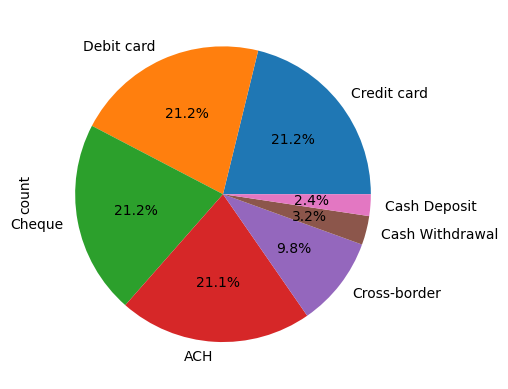

In [33]:
df['Payment_type'].value_counts().plot(kind='pie',autopct='%.1f%%')

In [34]:
df['Is_laundering'].value_counts()

,count
Is_laundering,
0,9494979
1,9873


<Axes: xlabel='Is_laundering'>

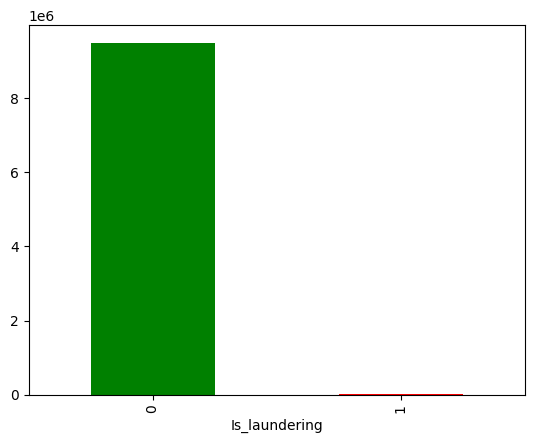

In [35]:
df['Is_laundering'].value_counts().plot(kind='bar',color=['green','red'])  # it is imbalanced Dataset

In [36]:
df['Laundering_type'].value_counts()

,count
Laundering_type,
Normal_Small_Fan_Out,3477717
Normal_Fan_Out,2302220
Normal_Fan_In,2104285
Normal_Group,528351
Normal_Cash_Withdrawal,305031
Normal_Cash_Deposits,223801
Normal_Periodical,210526
Normal_Plus_Mutual,155041
Normal_Mutual,125335


<Axes: xlabel='Laundering_type'>

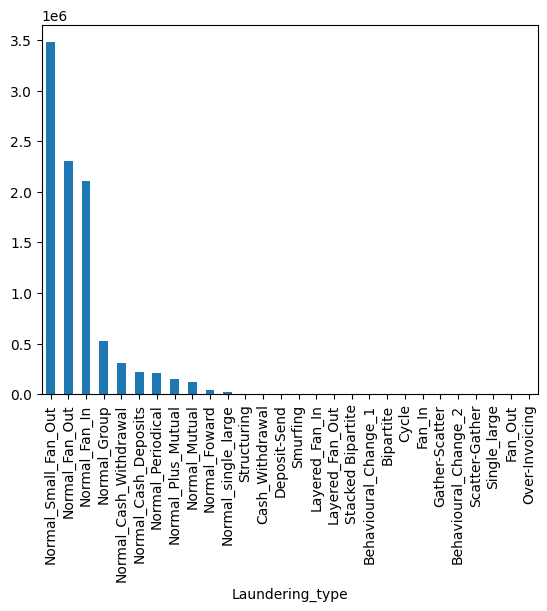

In [37]:
df['Laundering_type'].value_counts().plot(kind='bar')

<Axes: xlabel='Laundering_type'>

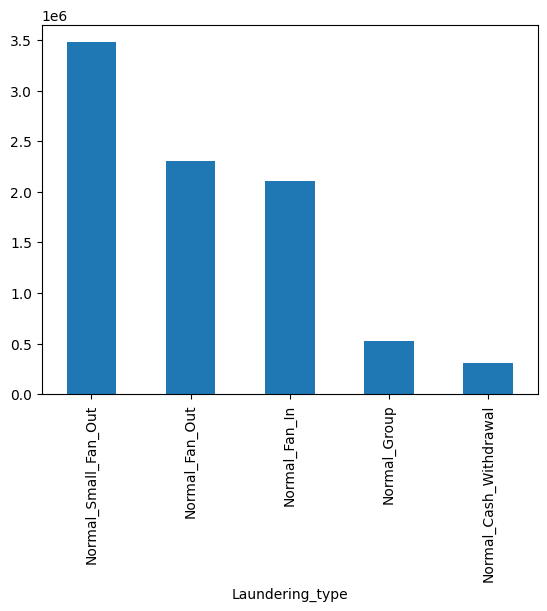

In [38]:
df['Laundering_type'].value_counts().nlargest(5).plot(kind='bar')

##### Bivariate Analysis

In [39]:
# categorical vs categorical

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

In [41]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

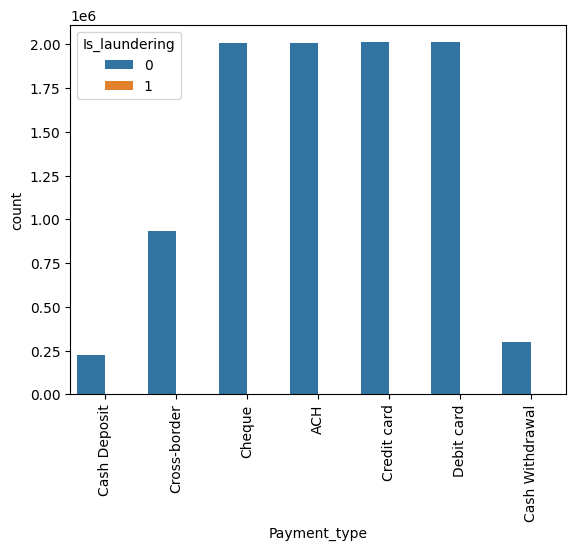

In [42]:
sns.countplot(x=df['Payment_type'],hue=df['Is_laundering'])
plt.xticks(rotation=90)
plt.show()

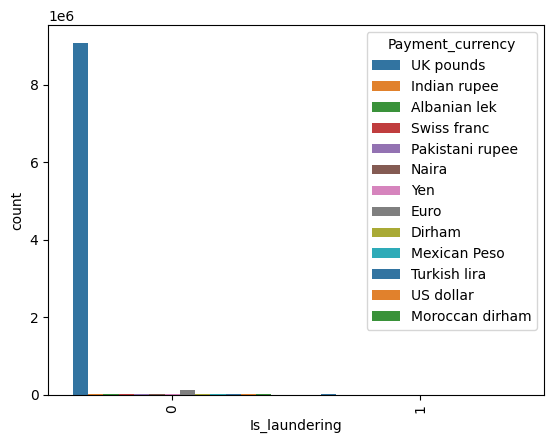

In [43]:
sns.countplot(hue=df['Payment_currency'],x=df['Is_laundering'],palette='tab10')
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='Is_laundering', ylabel='Amount'>

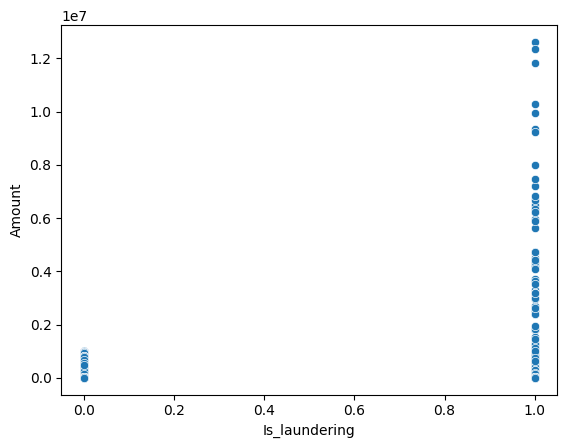

In [44]:
sns.scatterplot(x=df['Is_laundering'],y=df['Amount'])

In [45]:
# perform bivariate for more insights

#### Data Cleaning

In [46]:
df.dtypes

,0
Time,object
Date,object
Sender_account,int64
Receiver_account,int64
Amount,float64
Payment_currency,object
Received_currency,object
Sender_bank_location,object
Receiver_bank_location,object
Payment_type,object


In [47]:
df['Sender_account'] = df['Sender_account'].astype('str')
df['Receiver_account'] = df['Receiver_account'].astype('str')

In [48]:
df['Date']=df['Date'].astype('datetime64[ns]')

In [49]:
df['Date'].dt.year

,Date
0,2022
1,2022
2,2022
3,2022
4,2022
...,...
9504847,2023
9504848,2023
9504849,2023
9504850,2023


In [50]:
df['Date'].dt.month

,Date
0,10
1,10
2,10
3,10
4,10
...,...
9504847,8
9504848,8
9504849,8
9504850,8


In [51]:
df.columns

Index(['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount',
       'Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type', 'Is_laundering',
       'Laundering_type'],
      dtype='object')

In [52]:
df.drop(columns=['Time','Date','Laundering_type','Sender_account', 'Receiver_account'],inplace=True)

In [53]:
df = df.sample(n=100000,random_state=23)

In [54]:
df.shape

(100000, 7)

In [55]:
X=df.drop(columns=['Is_laundering'])
y = df['Is_laundering']

In [56]:
X.columns

Index(['Amount', 'Payment_currency', 'Received_currency',
       'Sender_bank_location', 'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [58]:
cat_columns = X.select_dtypes(include=['object']).columns
numerical_columns = X.select_dtypes(exclude=['object']).columns

In [59]:
cat_columns

Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')

In [60]:
numerical_columns

Index(['Amount'], dtype='object')

In [61]:
cat_transformer = Pipeline([('OHE',OneHotEncoder(dtype='int'))])

In [62]:
numerical_transformer = Pipeline([('Scaling',StandardScaler())])

In [63]:
preprocess = ColumnTransformer([('cat_transformer',cat_transformer,cat_columns),
                  ('numerical_transformer',numerical_transformer,numerical_columns)])

In [64]:
preprocess

ColumnTransformer(transformers=[('cat_transformer',
                                 Pipeline(steps=[('OHE',
                                                  OneHotEncoder(dtype='int'))]),
                                 Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')),
                                ('numerical_transformer',
                                 Pipeline(steps=[('Scaling',
                                                  StandardScaler())]),
                                 Index(['Amount'], dtype='object'))])

In [65]:
from collections import Counter

In [66]:
Counter(y)

Counter({0: 99887, 1: 113})

In [67]:
!pip install imblearn

In [68]:
from imblearn.over_sampling import SMOTE

In [69]:
import sklearn
print(sklearn.__version__)

1.6.1


In [70]:
#pip uninstall scikit-learn imbalanced-learn -y

In [71]:
#pip install scikit-learn==1.5.2 imbalanced-learn==0.12.4

In [72]:
resampling = Pipeline([('Preprocessing',preprocess),
         ('SMOTE',SMOTE(random_state=23))])

In [73]:
resampling

Pipeline(steps=[('Preprocessing',
                 ColumnTransformer(transformers=[('cat_transformer',
                                                  Pipeline(steps=[('OHE',
                                                                   OneHotEncoder(dtype='int'))]),
                                                  Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')),
                                                 ('numerical_transformer',
                                                  Pipeline(steps=[('Scaling',
                                                                   StandardScaler())]),
                                                  Index(['Amount'], dtype='object'))])),
                ('SMOTE', SMOTE(random_state=23))])

In [74]:
X_s,y_s = resampling.fit_resample(X,y)

In [75]:
Counter(y_s)

Counter({0: 99887, 1: 99887})

#### Model Building (Machine Learning)

**Approach**

1. Split the data into train and test sets **first** (stratified, so both sets keep the same small share of laundering cases).
2. Put preprocessing, SMOTE and the model inside one `imblearn` Pipeline. This way SMOTE only creates synthetic rows from the **training** data, and the test set stays real and untouched.
3. Train **5 baseline models** with default settings and compare them.
4. Tune the best baseline with **GridSearchCV**.
5. Because the data is highly imbalanced (~0.1% laundering), accuracy is misleading. We compare models mainly on **Recall, Precision, F1-score and ROC-AUC** of the suspicious class.

In [76]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             classification_report, confusion_matrix)

In [77]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=23)
print('Train:', X_train.shape, Counter(y_train))
print('Test :', X_test.shape, Counter(y_test))

Train: (80000, 6) Counter({0: 79910, 1: 90})
Test : (20000, 6) Counter({0: 19977, 1: 23})


In [78]:
# copy of the same preprocessing used above;
# handle_unknown='ignore' so a category not seen in training does not crash prediction
preprocess_ml = clone(preprocess)
preprocess_ml.set_params(cat_transformer__OHE__handle_unknown='ignore')

def make_pipeline(model):
    return Pipeline([('Preprocessing', preprocess_ml),
                     ('SMOTE', SMOTE(random_state=23)),
                     ('Model', model)])

In [79]:
def evaluate(name, pipe, X_test, y_test):
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    return {'Model': name,
            'Accuracy':  accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, zero_division=0),
            'Recall':    recall_score(y_test, y_pred),
            'F1':        f1_score(y_test, y_pred),
            'ROC_AUC':   roc_auc_score(y_test, y_prob),
            'PR_AUC':    average_precision_score(y_test, y_prob)}

##### Baseline Models

In [80]:
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=23),
    'KNN':                 KNeighborsClassifier(n_jobs=-1),
    'Decision Tree':       DecisionTreeClassifier(random_state=23),
    'Random Forest':       RandomForestClassifier(random_state=23, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=23)
}

In [81]:
results = []
fitted_baselines = {}

for name, model in baseline_models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)
    fitted_baselines[name] = pipe
    results.append(evaluate(name, pipe, X_test, y_test))
    print(f'{name} done')

baseline_results = pd.DataFrame(results).set_index('Model').sort_values('F1', ascending=False)
baseline_results.round(4)

Logistic Regression done
KNN done
Decision Tree done
Random Forest done
Gradient Boosting done


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.9170,0.0042,0.3043,0.0084,0.6968,0.0029
Random Forest,0.8053,0.0021,0.3478,0.0041,0.5377,0.0017
Decision Tree,0.8050,0.0021,0.3478,0.0041,0.5767,0.0015
KNN,0.8508,0.0020,0.2609,0.0040,0.5190,0.0014
Gradient Boosting,0.8943,0.0014,0.1304,0.0028,0.6665,0.0018


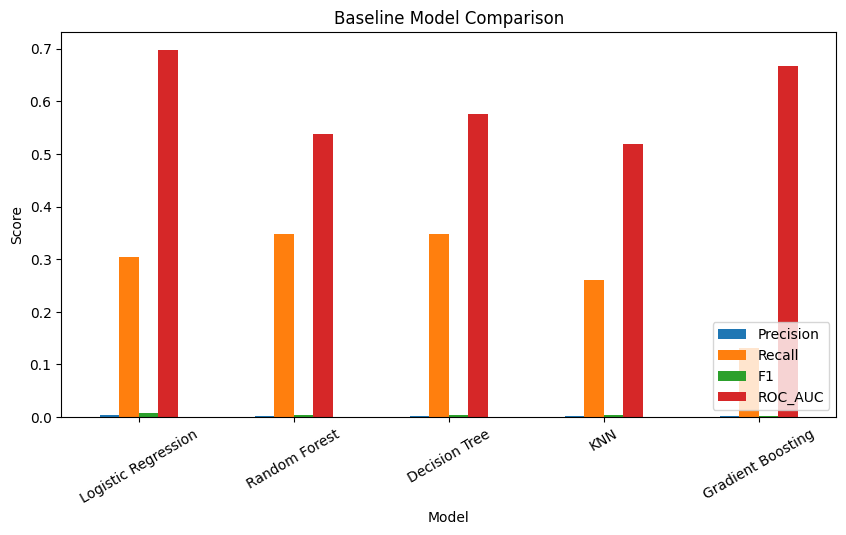

In [82]:
baseline_results[['Precision', 'Recall', 'F1', 'ROC_AUC']].plot(kind='bar', figsize=(10, 5))
plt.title('Baseline Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.show()

In [83]:
best_baseline_name = baseline_results.index[0]
print('Best baseline model (by F1):', best_baseline_name)

Best baseline model (by F1): Logistic Regression


##### Hyperparameter Tuning with GridSearchCV

The best baseline model is tuned with GridSearchCV using 3-fold stratified cross-validation.
`scoring='f1'` is used because we want a balance between catching laundering cases (recall) and not raising too many false alerts (precision).

In [84]:
param_grids = {
    'Logistic Regression': {'Model__C': [0.01, 0.1, 1, 10],
                            'Model__solver': ['lbfgs', 'liblinear']},
    'KNN':                 {'Model__n_neighbors': [3, 5, 7, 11],
                            'Model__weights': ['uniform', 'distance']},
    'Decision Tree':       {'Model__max_depth': [5, 10, 20, None],
                            'Model__min_samples_split': [2, 10],
                            'Model__criterion': ['gini', 'entropy']},
    'Random Forest':       {'Model__n_estimators': [100, 200],
                            'Model__max_depth': [10, 20, None],
                            'Model__min_samples_leaf': [1, 5]},
    'Gradient Boosting':   {'Model__n_estimators': [100, 200],
                            'Model__learning_rate': [0.05, 0.1],
                            'Model__max_depth': [3, 5]}
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=23)

grid = GridSearchCV(estimator=make_pipeline(clone(baseline_models[best_baseline_name])),
                    param_grid=param_grids[best_baseline_name],
                    scoring='f1',
                    cv=cv,
                    n_jobs=-1,
                    verbose=1)

In [85]:
grid.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=23, shuffle=True),
             estimator=Pipeline(steps=[('Preprocessing',
                                        ColumnTransformer(transformers=[('cat_transformer',
                                                                         Pipeline(steps=[('OHE',
                                                                                          OneHotEncoder(dtype='int',
                                                                                                        handle_unknown='ignore'))]),
                                                                         Index(['Payment_currency', 'Received_currency', 'Sender_bank_location',
       'Receiver_bank_location', 'Payment_type'],
      dtype='object')),
                                                                        ('numerical_transformer',
                                                                         Pipeline(steps=[('Scaling',
                                                                                          StandardScaler())]),
                                                                         Index(['Amount'], dtype='object'))])),
                                       ('SMOTE', SMOTE(random_state=23)),
                                       ('Model',
                                        LogisticRegression(max_iter=1000,
                                                           random_state=23))]),
             n_jobs=-1,
             param_grid={'Model__C': [0.01, 0.1, 1, 10],
                         'Model__solver': ['lbfgs', 'liblinear']},
             scoring='f1', verbose=1)

In [86]:
print('Best parameters :', grid.best_params_)
print('Best CV F1 score:', round(grid.best_score_, 4))
best_model = grid.best_estimator_

Best parameters : {'Model__C': 0.01, 'Model__solver': 'liblinear'}
Best CV F1 score: 0.007


##### Final Model Evaluation (on the untouched test set)

In [87]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Suspicious']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 4))
print('PR-AUC :', round(average_precision_score(y_test, y_prob), 4))

              precision    recall  f1-score   support

  Legitimate       1.00      0.88      0.94     19977
  Suspicious       0.01      0.52      0.01        23

    accuracy                           0.88     20000
   macro avg       0.50      0.70      0.47     20000
weighted avg       1.00      0.88      0.94     20000

ROC-AUC: 0.7619
PR-AUC : 0.0032


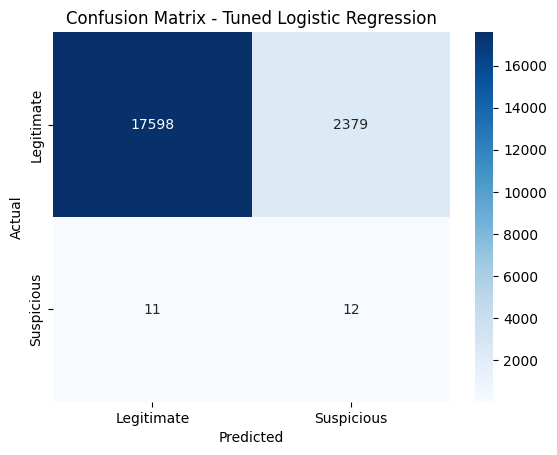

In [88]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Suspicious'],
            yticklabels=['Legitimate', 'Suspicious'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - Tuned {best_baseline_name}')
plt.show()

In [89]:
# baseline vs tuned comparison
tuned_row = pd.DataFrame([evaluate(f'Tuned {best_baseline_name}', best_model, X_test, y_test)]).set_index('Model')
final_comparison = pd.concat([baseline_results, tuned_row]).sort_values('F1', ascending=False)
final_comparison.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Tuned Logistic Regression,0.8805,0.0050,0.5217,0.0099,0.7619,0.0032
Logistic Regression,0.9170,0.0042,0.3043,0.0084,0.6968,0.0029
Random Forest,0.8053,0.0021,0.3478,0.0041,0.5377,0.0017
Decision Tree,0.8050,0.0021,0.3478,0.0041,0.5767,0.0015
KNN,0.8508,0.0020,0.2609,0.0040,0.5190,0.0014
Gradient Boosting,0.8943,0.0014,0.1304,0.0028,0.6665,0.0018


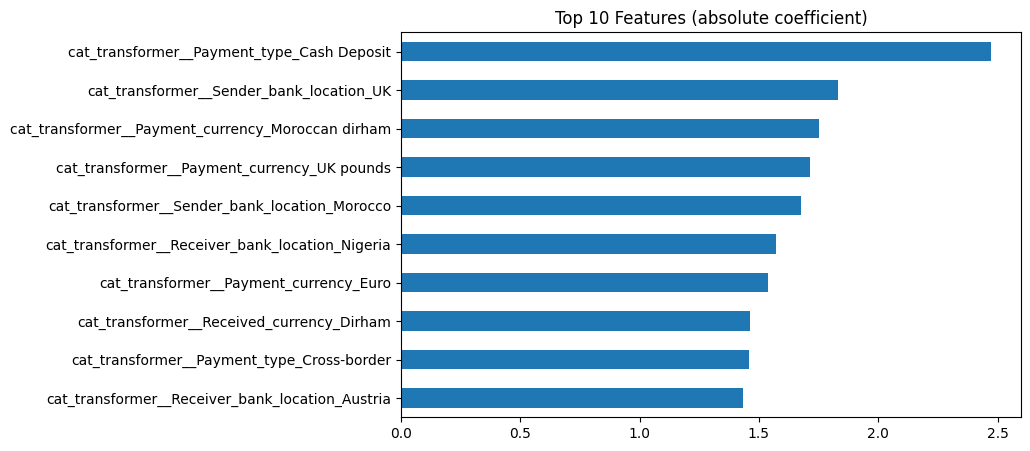

In [90]:
# which features the tuned model relies on most (only for tree-based models)
final_estimator = best_model.named_steps['Model']
if hasattr(final_estimator, 'feature_importances_'):
    feature_names = best_model.named_steps['Preprocessing'].get_feature_names_out()
    importances = pd.Series(final_estimator.feature_importances_, index=feature_names)
    importances.nlargest(10).sort_values().plot(kind='barh', figsize=(8, 5))
    plt.title('Top 10 Important Features')
    plt.show()
elif hasattr(final_estimator, 'coef_'):
    feature_names = best_model.named_steps['Preprocessing'].get_feature_names_out()
    coefs = pd.Series(abs(final_estimator.coef_[0]), index=feature_names)
    coefs.nlargest(10).sort_values().plot(kind='barh', figsize=(8, 5))
    plt.title('Top 10 Features (absolute coefficient)')
    plt.show()
else:
    print(f'{best_baseline_name} does not provide feature importances')

##### Saving the Model

In [91]:
import joblib
joblib.dump(best_model, 'AML_best_model.pkl')   # pipeline = preprocessing + SMOTE + tuned model

['AML_best_model.pkl']

##### Prediction Interface

In [92]:
model_loaded = joblib.load('AML_best_model.pkl')

def check_transaction(transaction: dict):
    row = pd.DataFrame([transaction])[X.columns]
    prob = model_loaded.predict_proba(row)[0, 1]
    label = 'SUSPICIOUS' if prob >= 0.5 else 'Legitimate'
    return label, round(prob, 4)

sample = X_test.iloc[0].to_dict()
print(sample)
check_transaction(sample)

{'Amount': 5360.96, 'Payment_currency': 'UK pounds', 'Received_currency': 'UK pounds', 'Sender_bank_location': 'UK', 'Receiver_bank_location': 'UK', 'Payment_type': 'Debit card'}


('Legitimate', np.float64(0.2914))

# Conclusion

- The goal was to build a machine learning model that can classify a transaction as **legitimate** or **suspicious**.
- EDA showed that the dataset is **highly imbalanced** (only about 0.1% of transactions are laundering), so accuracy alone was not a useful metric. Models were compared using **Precision, Recall, F1-score, ROC-AUC and PR-AUC** of the suspicious class.
- To handle the imbalance, **SMOTE** was applied inside the pipeline, only on the training data, so the test set reflects real-world class proportions and there is no data leakage.
- Five baseline models were trained: **Logistic Regression, KNN, Decision Tree, Random Forest and Gradient Boosting**. The best baseline (by F1-score) was then tuned with **GridSearchCV** using 3-fold stratified cross-validation.
- The tuned model was evaluated on the unseen test set and compared against all baselines (see `final_comparison`). The confusion matrix shows how many suspicious transactions are caught (true positives) and how many false alerts are raised (false positives), which directly relates to the bank's goals of better detection and fewer false alerts.
- The full pipeline (preprocessing + SMOTE + tuned model) is saved as `AML_best_model.pkl`, and a simple `check_transaction()` function returns a label and a probability for a new transaction, which can support real-time transaction monitoring.

**Limitations and future work**
- Only 100,000 transactions were sampled, which leaves very few laundering cases for training and testing. Using a larger sample (or keeping all laundering rows and sampling only the legitimate ones) would give more reliable results.
- Account-level behaviour features (for example, number of transactions per sender, average amount per sender, time/date patterns) were dropped; adding them could help catch more sophisticated laundering patterns.
- The decision threshold (0.5) can be adjusted to trade off recall against false alerts, depending on how many alerts the compliance team can investigate.